# IND320 - Project work, part 4: currency, time zones, forecasting and the final app

- **Student:** Iftikhar Amiri
- **GitHub repository:** https://github.com/iftikharamiri/ind320 (part 4 was developed on the branch `part4` and merged into `main`)
- **Streamlit app:** https://ind320-iftikhar-amiri.streamlit.app/
- **Screencast:** https://github.com/iftikharamiri/ind320/raw/main/screencast/part4_screencast.mp4
  (the link downloads the video. On the GitHub file page, click **View raw** if the file is too big to preview.)

## Contents
1. Setup
2. App structure: the sketch and the design choices
3. Norges Bank: exchange rates for EUR and USD
4. Time zones in Magasinstatistikk, ENTSO-E, open-meteo and Norges Bank
5. Weekly weather history per area (for the map, correlations and forecasts)
6. Forecasting the reservoir filling with River
7. Sliding window correlation: weather and reservoirs
8. AI usage
9. Log

## 1. Setup
Kernel **IND320 Spark (Python 3.11)**, as in parts 2 and 3 (Spark is not used here).
The functions shown in this notebook are the same code as in the app's `modules/` folder,
so the notebook and the app always agree. Plotly figures are shown as static images
here (the `png` renderer), so they appear in the PDF; in the app they are interactive.

In [1]:
import json
import time
import warnings
from pathlib import Path
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import requests
from pymongo import MongoClient

# pandas 3 announces a future change of concat's sorting; it does not affect the results here
warnings.filterwarnings("ignore", message=".*Sorting by default.*")
warnings.filterwarnings("ignore", message=".*obj.round has no effect.*")

# Static images of the Plotly figures, so they survive the PDF export
pio.renderers.default = "png"
pio.renderers["png"].width, pio.renderers["png"].height = 1000, 420

# The app's "Nordic water" colours (modules/palette.py), so plots match the app theme
FJORD, CORAL, TEAL, SAND, MOSS, SLATE = "#0b5e7e", "#e4572e", "#1b9aaa", "#e9b44c", "#3a8f6e", "#4a5d6b"
PALETTE = [FJORD, CORAL, TEAL, SAND, MOSS, "#6c5b9e", SLATE, "#7cc6d6"]
pio.templates["nordic"] = go.layout.Template(layout=dict(colorway=PALETTE, font=dict(family="Source Sans 3, Arial"),
                                                           plot_bgcolor="#f4f8fa", paper_bgcolor="white"))
pio.templates.default = "plotly_white+nordic"

# Passwords live outside the repository (see part 2)
SECRETS = Path("../../course-material/No_sync")
mongo_user, mongo_password = (SECRETS / "MongoDB").read_text().split("\n")[:2]
mongo = MongoClient(
    f"mongodb+srv://{quote_plus(mongo_user.strip())}:{quote_plus(mongo_password.strip())}"
    "@ind320.w1oh2ln.mongodb.net/",
    serverSelectionTimeoutMS=20000,
)
db = mongo["ind320"]
print("MongoDB ping:", mongo.admin.command("ping"))

MongoDB ping: {'ok': 1}


## 2. App structure: the sketch and the design choices
Before changing any code, I listed every page and element the app should have after part 4
and drew how they fit together (drawn in Figma, file
`notebooks/figures/app_structure_sketch.png`):

![App structure sketch](figures/app_structure_sketch.png)

**Ordering by type of task.** The pages are grouped by what the user wants to do, not by
data source, because several pages now combine sources (weather + reservoirs, weather +
currency + reservoirs in the forecast):
- **Overview:** the map is the front page. It shows where the areas are, colours them by
  fill level or weather, and is the main selector: a click selects an area for all pages.
  Below the map, links point to the three analysis groups.
- **Explore:** reservoir data (plots and the overview table), weather vs reservoirs
  (sliding window correlation), power exchange (ENTSO-E) and exchange rates (Norges Bank).
- **Anomalies:** weather outliers (SPC, LOF) and reservoir patterns (STL, spectrogram).
- **Predict:** the River forecast of the reservoir filling.

**The LineChartColumn page** did not need its own page any more. It shows the same
interval of NVE data as the plots, so it became the second tab of "Reservoir data", with
one shared interval slider (before, the table page silently depended on a slider on
another page).

**Global vs local selections.** The *area* is global: it is chosen in the sidebar or by
clicking the map, and every page uses it (session state keys `area_type`, `area`). The
*month* chosen on the map is global too (`period`), and the forecast starts there. Things
that only make sense on one page stay local: year and number of locations on the weather
page, DCT cut-off, window length and lag, model parameters.

**Theme.** A "Nordic water" theme in `.streamlit/config.toml`: deep fjord blue, teal and
glacier tones on a calm light background, a dark blue sidebar, and coral as the one
contrast colour (outliers, anomalies, the selected area, the forecast). The same colours
are set as Streamlit's chart colours and in `modules/palette.py`, so the charts match the theme
automatically. Each group has a coloured badge above the page title and its own icon.

**Plots.** All matplotlib and Altair figures in the app were replaced by Plotly (zoom,
hover, animation), so every chart looks and behaves the same way. The peer review of part 3
asked for exactly this consistency.

## 3. Norges Bank: exchange rates for EUR and USD
Norges Bank publishes its exchange rates through an open SDMX API. The
series key `B.EUR+USD.NOK.SP` means business-day (B) rates of euro and US dollar against
the krone, spot (SP). The function asks for CSV and turns it into one column per currency.

In [2]:
from io import StringIO

NB_URL = 'https://data.norges-bank.no/api/data/EXR'


def download_rates(
    currencies: tuple[str, ...] = ("EUR", "USD"),
    start: str = "2015-01-01",
    end: str | None = None,
    frequency: str = "B",
) -> pd.DataFrame:
    """Exchange rates in NOK per unit of each currency, one column per currency.

    Parameters
    ----------
    currencies : ISO codes, e.g. ("EUR", "USD")
    start, end : first and last date, "YYYY-MM-DD" (end=None means up to today)
    frequency : "B" business days (daily), "M" monthly or "A" annual averages

    The daily ("B") rates are fixed once per business day at 14:15 Oslo time
    (the ECB concertation), so they are dates without a time of day, and weekends
    and Norwegian bank holidays are missing.
    """
    key = f"{frequency}.{'+'.join(currencies)}.NOK.SP"
    params = {"format": "csv", "locale": "en", "startPeriod": start}
    if end:
        params["endPeriod"] = end
    response = requests.get(f"{NB_URL}/{key}", params=params, timeout=60)
    response.raise_for_status()
    # Semicolon-separated table with one row per currency and date
    raw = pd.read_csv(StringIO(response.text), sep=";")
    rates = raw.pivot(index="TIME_PERIOD", columns="BASE_CUR", values="OBS_VALUE")
    # str first: yearly periods ("2015") are read as integers, which to_datetime
    # would take as nanoseconds since 1970
    rates.index = pd.to_datetime(rates.index.astype(str))
    rates.index.name = "date"
    rates.columns.name = None
    return rates.astype(float).sort_index()


def weekly_rates(rates: pd.DataFrame) -> pd.DataFrame:
    """Daily rates -> weekly means, weeks labelled by their Sunday like Magasinstatistikk."""
    return rates.resample("W-SUN").mean().dropna(how="all")

In [3]:
# Test: daily rates since 2015, and Norges Bank's own monthly averages
rates = download_rates(("EUR", "USD"), start="2015-01-01")
monthly = download_rates(("EUR", "USD"), start="2015-01-01", frequency="M")
print(rates.shape[0], "business days,", rates.index.min().date(), "-", rates.index.max().date())
print("weekdays present:", sorted(rates.index.dayofweek.unique()), "(0 = Monday; no weekends)")
rates.tail()

2995 business days, 2015-01-02 - 2026-11-24
weekdays present: [0, 1, 2, 3, 4] (0 = Monday; no weekends)


,EUR,USD
date,,
2026-11-18,10.6045,9.6686
2026-11-19,10.6475,9.6866
2026-11-20,10.7180,9.7525
2026-11-23,10.7285,9.8076
2026-11-24,10.7350,9.7920


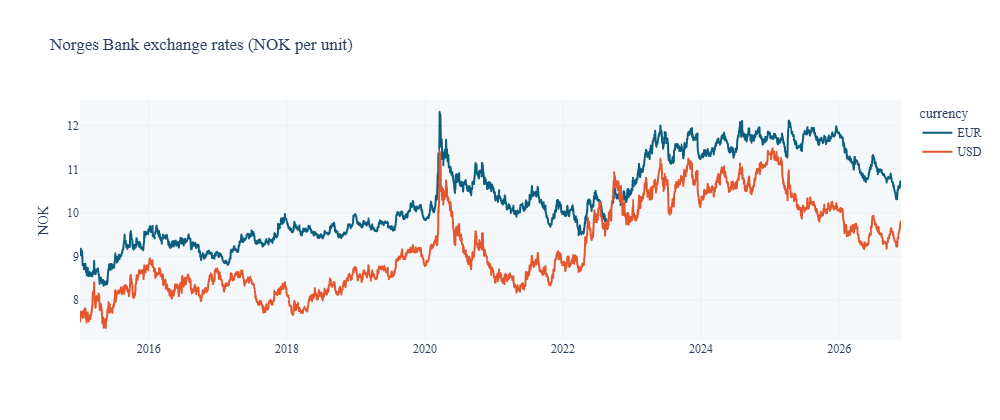

In [4]:
# The krone against the euro and the dollar since 2015
fig = px.line(rates.reset_index().melt(id_vars="date", var_name="currency", value_name="NOK"),
              x="date", y="NOK", color="currency", color_discrete_map={"EUR": FJORD, "USD": CORAL},
              title="Norges Bank exchange rates (NOK per unit)", labels={"date": ""})
fig.show()

**Findings.** The function works: about 3000 business days of EUR/NOK and USD/NOK since
2015, and the same API gives Norges Bank's own monthly and annual averages by changing one
letter in the series key (`frequency`). The krone weakened clearly over the period, most in
2020 (the corona shock) and 2022–2023. For the forecasts the daily rates are averaged to the
same weeks as the reservoirs (`weekly_rates`).

## 4. Time zones in the four data sources
When data from several APIs are combined, a mismatch in time zones shifts one series
against the other. Norway uses CET (UTC+1) in winter and CEST (UTC+2) in summer, so
local time and UTC differ by one or two hours, and one local day per year has 23 hours
and one has 25. Below, each source is checked with code.

**Magasinstatistikk (NVE).** Dates without a time of day.

In [5]:
nve_raw = requests.get("https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData", timeout=60).json()
print("dato_Id examples:", [r["dato_Id"] for r in nve_raw[:3]])
print("publishing time example:", nve_raw[0]["neste_Publiseringsdato"])
dates = pd.to_datetime(pd.Series([r["dato_Id"] for r in nve_raw]))
print("weekday of dato_Id:", dates.dt.day_name().value_counts().to_dict())
# Does the ISO week in the data match the date? (dato_Id is the Sunday ending the week)
iso = pd.DataFrame(nve_raw)
iso["dato_Id"] = pd.to_datetime(iso["dato_Id"])
print("ISO week matches the date:", (iso["dato_Id"].dt.isocalendar().week == iso["iso_uke"]).mean())

dato_Id examples: ['2020-11-15', '2011-08-28', '1998-07-05']
publishing time example: 2020-11-25T13:00:00
weekday of dato_Id: {'Sunday': 14976}
ISO week matches the date: 1.0


**ENTSO-E.** The hourly cross-border flows from part 2, as cached by the download.

In [6]:
flow = pd.read_csv("../data/cache/flow_NO_2_DK_1_20241021_20261021.csv", index_col=0)
print("first timestamps as stored:", list(flow.index[:2]))
flow.index = pd.to_datetime(flow.index, utc=True)
local = flow.tz_convert("Europe/Oslo")
# Hours per local calendar day around the two clock changes of 2025
hours = local.groupby(local.index.date).size()
print("hours per local day:", hours.loc[[pd.Timestamp("2025-03-29").date(), pd.Timestamp("2025-03-30").date(),
                                          pd.Timestamp("2025-10-26").date(), pd.Timestamp("2025-10-27").date()]].to_dict())

first timestamps as stored: ['2024-10-21 00:00:00+00:00', '2024-10-21 01:00:00+00:00']


hours per local day: {datetime.date(2025, 3, 29): 24, datetime.date(2025, 3, 30): 23, datetime.date(2025, 10, 26): 25, datetime.date(2025, 10, 27): 24}


**open-meteo.** The time zone is a request parameter (`timezone`); the default is GMT.

In [7]:
def om(timezone, resolution, variable, start, end):
    # One small open-meteo request (point in Oslo), returning time stamps and values
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", params={
        "latitude": 59.91, "longitude": 10.75, "start_date": start, "end_date": end,
        resolution: variable, "models": "era5", "timezone": timezone}, timeout=60).json()
    return pd.Series(r[resolution][variable], index=pd.to_datetime(r[resolution]["time"]), name=timezone), r["utc_offset_seconds"]

# Hourly: the clock-change day 30 March 2025 in UTC and in Oslo time
for tz in ("UTC", "Europe/Oslo"):
    s, offset = om(tz, "hourly", "temperature_2m", "2025-03-30", "2025-03-30")
    print(f"{tz:12s} offset {offset // 3600} h, {len(s)} hours, first stamps {[t.strftime('%H:%M') for t in s.index[:4]]}")
# Daily sums depend on where the day starts: precipitation in a rainy week, UTC vs Oslo days
utc, _ = om("UTC", "daily", "precipitation_sum", "2024-09-02", "2024-09-15")
oslo, _ = om("Europe/Oslo", "daily", "precipitation_sum", "2024-09-02", "2024-09-15")
compare = pd.concat([utc, oslo], axis=1)
compare["difference"] = compare["Europe/Oslo"] - compare["UTC"]
compare

UTC          offset 0 h, 24 hours, first stamps ['00:00', '01:00', '02:00', '03:00']
Europe/Oslo  offset 1 h, 24 hours, first stamps ['00:00', '01:00', '02:00', '03:00']


,UTC,Europe/Oslo,difference
2024-09-02,14.0,14.0,0.0
2024-09-03,16.2,16.2,0.0
2024-09-04,5.8,5.7,-0.1
2024-09-05,0.0,0.1,0.1
2024-09-06,0.0,0.0,0.0
2024-09-07,0.9,0.4,-0.5
2024-09-08,5.7,5.4,-0.3
2024-09-09,25.4,26.1,0.7
2024-09-10,10.0,10.1,0.1
2024-09-11,0.9,0.9,0.0


**Norges Bank.** Business-day dates; the rate is fixed at 14:15 Oslo time.

In [8]:
print("first dates:", [d.strftime("%a %d %b %Y") for d in rates.index[:5]])
# Which weekdays in 2025 have no rate? (weekends and Norwegian bank holidays)
all_days = pd.bdate_range("2025-01-01", "2025-12-31")
missing = all_days.difference(rates.index)
print("business days without a rate in 2025:", [d.strftime("%d %b") for d in missing])

first dates: ['Fri 02 Jan 2015', 'Mon 05 Jan 2015', 'Tue 06 Jan 2015', 'Wed 07 Jan 2015', 'Thu 08 Jan 2015']
business days without a rate in 2025: ['01 Jan', '17 Apr', '18 Apr', '21 Apr', '01 May', '29 May', '09 Jun', '24 Dec', '25 Dec', '26 Dec']


**Findings and solutions.**

| Source | How time is given | Problem when combining | Solution |
|---|---|---|---|
| Magasinstatistikk | a date (`dato_Id`), always the Sunday that ends ISO week `iso_uke` | none by itself, but it is a *week*, not a moment | use it as the label of the week Monday–Sunday |
| ENTSO-E | hourly time stamps in UTC (`+00:00`) | a local day has 23 or 25 hours at the clock changes; UTC days are shifted 1–2 h | convert with `tz_convert("Europe/Oslo")` before grouping by day or week |
| open-meteo | local time of the `timezone` parameter, GMT by default | daily sums depend on where the day starts (up to 0.7 mm per day above) | ask for `timezone=Europe/Oslo`, so days are Norwegian calendar days |
| Norges Bank | business-day dates (rate fixed at 14:15 Oslo time); no weekends or bank holidays | gaps on holidays; no values on Sundays, the reservoir label day | average the business days of each Monday–Sunday week |

So the common ground is **Norwegian local calendar days aggregated to weeks that end on
Sunday** (`resample("W-SUN")`). With that, all sources line up exactly with the reservoir
weeks, and the remaining time-zone error (at most two hours at the edge of a week) is far
below the weekly resolution.

## 5. Weekly weather history per area
The map (colour by weather property), the sliding window correlation and the exogenous
inputs of the forecasts all need several years of weather for every Magasinstatistikk
area. Downloading this live in the app would use far too much of open-meteo's free quota,
so it is done once here and stored in MongoDB, from where the app reads it.

**Choices.** Daily ERA5 values from 2015 for 5 of the 1000 random land points of each area
(part 3), days in Norwegian local time (section 4). A year counts as about 26 API calls
per point, so 8 areas x 5 points x 12 years is about 12 000 calls. That is more than the
free daily (10 000) and hourly (5 000) limits, so the download keeps every point in a file
and continues where it stopped; it ran over two days. "Norway" is the mean of the five
price areas. Daily values become weeks labelled by their Sunday, exactly like the reservoir
weeks: sums for amounts (precipitation, snow, radiation), means for states (temperature,
wind).

In [9]:
DAILY_VARIABLES = ['temperature_2m_mean', 'precipitation_sum', 'rain_sum', 'snowfall_sum', 'wind_speed_10m_mean', 'relative_humidity_2m_mean', 'cloud_cover_mean', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration']

WEEKLY_HOW = {'temperature_2m_mean': 'mean', 'precipitation_sum': 'sum', 'rain_sum': 'sum', 'snowfall_sum': 'sum', 'wind_speed_10m_mean': 'mean', 'relative_humidity_2m_mean': 'mean', 'cloud_cover_mean': 'mean', 'shortwave_radiation_sum': 'sum', 'et0_fao_evapotranspiration': 'sum'}

ARCHIVE_URL = 'https://archive-api.open-meteo.com/v1/archive'


def _download_point(
    lon: float,
    lat: float,
    start: str,
    end: str,
    variables: list[str],
    resolution: str = "hourly",
    timezone: str = "UTC",
) -> dict:
    """One open-meteo request for one location; retried on rate limits and server errors.

    open-meteo answers HTTP 429 when too many requests arrive at once, and now and then
    a 5xx. Waiting 2, 4, 8, ... seconds and trying again is the standard remedy.
    `resolution` is "hourly" or "daily". Daily values are sums/means over a calendar
    day in `timezone`, so for daily data the time zone matters (see part 4 notebook).
    """
    params = {
        "latitude": round(lat, 4),
        "longitude": round(lon, 4),
        "start_date": start,
        "end_date": end,
        resolution: ",".join(variables),
        "models": "era5",  # the reanalysis model asked for in the assignment
        "timezone": timezone,
    }
    for attempt in range(6):
        response = requests.get(ARCHIVE_URL, params=params, timeout=300)
        if response.status_code == 200:
            return response.json()
        if response.status_code == 429:
            # The per-minute limit passes in seconds, so waiting helps. The hourly and
            # daily limits do not, so fail at once with open-meteo's own explanation
            # instead of letting the user wait minutes for nothing.
            reason = response.json().get("reason", "") if response.content else ""
            if "Hourly" in reason or "Daily" in reason:
                raise RuntimeError(f"open-meteo: {reason}")
        if response.status_code == 429 or response.status_code >= 500:
            time.sleep(2 ** (attempt + 1))
            continue
        response.raise_for_status()  # 4xx other than 429: a wrong request, no point retrying
    raise RuntimeError(f"open-meteo kept refusing the request (HTTP {response.status_code})")


def download_daily_point(lon: float, lat: float, start: str, end: str) -> pd.DataFrame:
    """Daily ERA5 values for one point, days in Norwegian local time (Europe/Oslo).

    Local days are used because the reservoir weeks (Magasinstatistikk) and the currency
    rates (Norges Bank) are Norwegian calendar dates, not UTC.
    """
    answer = _download_point(lon, lat, start, end, DAILY_VARIABLES, "daily", "Europe/Oslo")
    daily = pd.DataFrame(answer["daily"])
    daily["time"] = pd.to_datetime(daily["time"])
    return daily


def to_weekly(daily: pd.DataFrame) -> pd.DataFrame:
    """Daily values -> ISO weeks (Monday-Sunday), labelled by the Sunday.

    Magasinstatistikk dates each week by its Sunday, so this label makes the weather
    weeks line up exactly with the reservoir weeks. Incomplete weeks are dropped.
    """
    daily = daily.set_index("time").sort_index()
    weekly = daily[list(WEEKLY_HOW)].resample("W-SUN").agg(WEEKLY_HOW)
    days = daily[list(WEEKLY_HOW)[0]].resample("W-SUN").count()
    return weekly[days == 7]

In [10]:
# Download (or read from the cache) 5 points per area; the points come from MongoDB (part 3)
locations = pd.DataFrame(list(db["locations"].find({}, {"_id": 0})))
CACHE = Path("../data/cache/daily"); CACHE.mkdir(parents=True, exist_ok=True)   # git-ignored
START, END = "2015-01-01", "2026-11-13"
AREAS = ["NO1", "NO2", "NO3", "NO4", "NO5", "VASS1", "VASS2", "VASS3"]
for area in AREAS:
    for row in locations[locations["area"] == area].sort_values("order").head(5).itertuples():
        path = CACHE / f"{area}_{row.order}_{START}_{END}.csv"
        if not path.exists():                       # only the missing points are downloaded
            download_daily_point(row.lon, row.lat, START, END).to_csv(path, index=False)
print(len(list(CACHE.glob("*.csv"))), "point files")

40 point files


In [11]:
# Daily mean over the 5 points of each area -> weeks; app names for the watercourse areas
APP_NAME = {"VASS1": "Watercourse 1", "VASS2": "Watercourse 2", "VASS3": "Watercourse 3"}
frames = {}
for area in AREAS:
    files = sorted(CACHE.glob(f"{area}_*_{START}_{END}.csv"))
    daily = pd.concat([pd.read_csv(f, parse_dates=["time"]) for f in files]).groupby("time").mean().reset_index()
    frames[APP_NAME.get(area, area)] = to_weekly(daily)
frames["Norway"] = sum(frames[a] for a in ["NO1", "NO2", "NO3", "NO4", "NO5"]) / 5
weather_weekly = pd.concat(frames, names=["area", "week"]).reset_index()

# Store in MongoDB (replacing the old version), one document per area and week
col = db["weather_weekly"]
col.delete_many({})
col.insert_many(weather_weekly.round(3).to_dict("records"))
col.create_index([("area", 1), ("week", 1)])
print("documents in MongoDB:", col.count_documents({}))
weather_weekly.groupby("area")["week"].agg(["count", "min", "max"])

documents in MongoDB: 5562


,count,min,max
area,,,
NO1,618,2015-01-11,2026-11-08
NO2,618,2015-01-11,2026-11-08
NO3,618,2015-01-11,2026-11-08
NO4,618,2015-01-11,2026-11-08
NO5,618,2015-01-11,2026-11-08
Norway,618,2015-01-11,2026-11-08
Watercourse 1,618,2015-01-11,2026-11-08
Watercourse 2,618,2015-01-11,2026-11-08
Watercourse 3,618,2015-01-11,2026-11-08


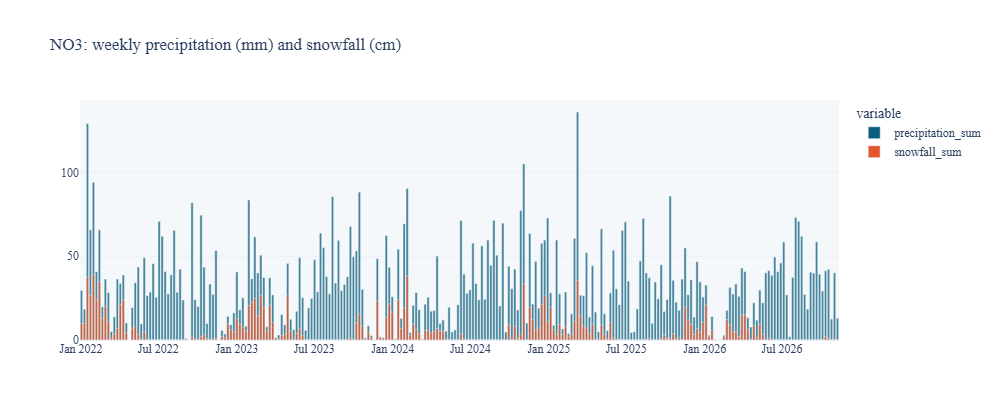

In [12]:
# Weekly snowfall and precipitation in NO3: the winter snow is the water that fills the
# reservoirs in May-June
w3 = weather_weekly[weather_weekly["area"] == "NO3"].set_index("week")
fig = px.bar(w3.loc["2022":, ["precipitation_sum", "snowfall_sum"]].reset_index().melt(id_vars="week"),
             x="week", y="value", color="variable", barmode="overlay", opacity=0.75,
             title="NO3: weekly precipitation (mm) and snowfall (cm)", labels={"week": "", "value": ""})
fig.show()

**Map outlines.** In part 3 the area outlines were downloaded from NVE's map services as
GeoJSON (which needs no conversion; a shapefile would have to be converted, e.g. with
`geopandas.read_file(...).to_file(..., driver="GeoJSON")`). For the app's map, the price
areas, the merged NVE regions (Watercourse 1 = RS+RØ, 2 = RV, 3 = RM+RN) and Norway are
written into one small file with simplified coastlines, so the map loads fast:

In [13]:
from shapely.geometry import shape, mapping
from shapely.ops import unary_union

A = Path("../data/areas")
def load(name, field):
    return {f["properties"][field]: shape(f["geometry"]).buffer(0)
            for f in json.loads((A / name).read_text(encoding="utf-8"))["features"]}
price = {k.replace(" ", ""): v for k, v in load("price_areas.geojson", "budomr").items()}
reg = load("nve_regions.geojson", "REGION")
areas = {**price, "Norway": unary_union(list(price.values())),
         "Watercourse 1": unary_union([reg["RS"], reg["RØ"]]), "Watercourse 2": reg["RV"],
         "Watercourse 3": unary_union([reg["RM"], reg["RN"]])}
def rounded(g):   # simplify (~500 m) and round coordinates to 3 decimals: small file
    return json.loads(json.dumps(mapping(g.simplify(0.005, preserve_topology=True))),
                      parse_float=lambda x: round(float(x), 3))
fc = {"type": "FeatureCollection", "features": [
    {"type": "Feature", "id": k, "properties": {"area": k}, "geometry": rounded(g)} for k, g in areas.items()]}
text = json.dumps(fc, separators=(",", ":"))
(A / "map_areas.geojson").write_text(text, encoding="utf-8")
print(f"{len(text) // 1024} kB:", list(areas))

49 kB: ['NO1', 'NO2', 'NO3', 'NO4', 'NO5', 'Norway', 'Watercourse 1', 'Watercourse 2', 'Watercourse 3']


## 6. Forecasting the reservoir filling with River
**Task.** A function that forecasts the coming months' fill level for one Magasinstatistikk
area with River, where the model parameters, the length of the history, the horizon and
the data sources (exogenous variables) are inputs.

**Time resolution.** Weekly. It is the native resolution of Magasinstatistikk (a finer one
would need invented values between the weekly measurements), the weather and currency can
be aggregated to the same Sunday-labelled weeks without loss of meaning (section 4), and a
model with 10 years of weekly history trains in a fraction of a second (measured below).
Monthly data would be even faster, but leave only ~120 training points and a forecast of
"the coming months" with just a handful of steps.

**Method** (details in the docstring):
1. Remove the normal seasonal curve (mean fill of each ISO week over the training years)
   and forecast the *anomaly*.
2. River model on the anomaly: `time_series.SNARIMAX` or a lag-based linear regression.
   Exogenous variables enter as their own anomalies: this week's value and the mean of the
   last `memory` weeks (a snowy winter is a snowpack that fills the reservoirs months later).
3. Dynamic forecasting: every forecast week is fed back as a lag.
4. Confidence band (bonus): linear models with River's `optim.losses.Quantile` loss.

In [14]:
import time

import numpy as np
import pandas as pd
from river import linear_model, optim, preprocessing, time_series

LIMIT = 6.0

MODELS = {'snarimax': 'SNARIMAX (seasonal ARIMA)', 'lag_ml': 'Lag-based ML (linear regression)'}


def _week(index: pd.DatetimeIndex) -> np.ndarray:
    """ISO week number, with week 53 folded into 52 (it only exists in some years)."""
    return np.minimum(index.isocalendar().week.to_numpy(dtype=int), 52)


def _climatology(series: pd.Series) -> pd.Series:
    """Mean value per ISO week (1-52) over the given series."""
    return series.groupby(_week(series.index)).mean()


def _anomaly(series: pd.Series, clim: pd.Series) -> pd.Series:
    """Series minus its climatology, aligned on ISO week."""
    return series - clim.reindex(_week(series.index)).to_numpy()


def _exog_features(exog_anom: pd.DataFrame, memory: int) -> pd.DataFrame:
    """Two features per exogenous variable: this week's anomaly and the mean of the last
    `memory` weeks. Columns are standardised later by the model pipeline."""
    feats = {}
    for col in exog_anom.columns:
        feats[f"{col}"] = exog_anom[col]
        feats[f"{col}_mean{memory}w"] = exog_anom[col].rolling(memory, min_periods=1).mean()
    return pd.DataFrame(feats, index=exog_anom.index)


def _regressor(learning_rate: float, loss=None):
    """Standardise the inputs, then an online linear regression.

    AdaGrad instead of plain SGD: in the notebook tests, SGD diverged (errors of 1e+80)
    as soon as exogenous inputs were added, because each step's error is fed back into
    the next forecast. AdaGrad shrinks the step size per feature and stayed stable.
    A small L2 penalty keeps the weights from growing on correlated inputs.
    """
    kwargs = {"optimizer": optim.AdaGrad(learning_rate), "intercept_lr": learning_rate, "l2": 0.001}
    if loss is not None:
        kwargs["loss"] = loss
    return preprocessing.StandardScaler() | linear_model.LinearRegression(**kwargs)


def forecast_fill(
    fill: pd.Series,
    exog: pd.DataFrame | None = None,
    origin: str | pd.Timestamp | None = None,
    history_weeks: int = 520,
    horizon_weeks: int = 26,
    model: str = "lag_ml",
    p: int = 2,
    d: int = 0,
    q: int = 0,
    sp: int = 0,
    sd: int = 0,
    sq: int = 0,
    memory: int = 13,
    learning_rate: float = 0.01,
    future_exog: str = "observed",
    quantiles: tuple[float, float] | None = (0.1, 0.9),
) -> dict:
    """Forecast the weekly fill level of one area.

    Parameters
    ----------
    fill : weekly fill level (0-1) of ONE area, indexed by the Sunday of each week
    exog : weekly exogenous variables on the same weekly index (or None). Which
        columns are passed is the "selection of data sources" (weather, currency).
    origin : last week that is known; the forecast starts the week after.
        None = the latest week in the data (a real forecast into the future).
    history_weeks : length of the training history before the origin
    horizon_weeks : how many weeks to forecast
    model : "snarimax" or "lag_ml"
    p, d, q : SNARIMAX order; for "lag_ml", p is the number of lags of the anomaly
    sp, sd, sq : seasonal SNARIMAX order (season m = 52 weeks); ignored by "lag_ml"
    memory : weeks in the rolling mean of each exogenous anomaly
    learning_rate : AdaGrad step size of the online linear models
    future_exog : how exogenous inputs are filled in after the origin:
        "observed" uses the real values when they exist (a backtest; not possible
        for a true future forecast), "climatology" uses normal weather (anomaly 0).
    quantiles : (low, high) quantiles of the confidence band, or None for no band

    Returns a dict with
        forecast : DataFrame indexed by week: forecast, lower, upper, actual (if known)
        train : the training series (for plotting)
        mae : mean absolute error against the actual values (None if unknown)
        seconds : time spent training and forecasting
    """
    t0 = time.time()
    fill = fill.dropna().sort_index()
    origin = fill.index[-1] if origin is None else pd.Timestamp(origin)
    train = fill[fill.index <= origin].iloc[-history_weeks:]
    if len(train) < 104:
        raise ValueError("At least two years of history are needed before the origin.")
    future = pd.date_range(train.index[-1] + pd.Timedelta(weeks=1), periods=horizon_weeks, freq="W-SUN")

    # 1. Deseasonalise the target with its climatology from the training years only
    clim = _climatology(train)
    anom = _anomaly(train, clim)

    # Exogenous anomalies on the training weeks and the forecast weeks
    feats = None
    if exog is not None and exog.shape[1] > 0:
        exog = exog.sort_index()
        exog_train = exog.loc[(exog.index >= train.index[0]) & (exog.index <= origin)]
        exog_clim = exog_train.groupby(_week(exog_train.index)).mean()
        weeks = train.index.append(future)
        ex = exog.reindex(weeks)
        if future_exog == "climatology":
            ex.loc[future] = np.nan  # pretend the future weather is unknown
        ex_anom = ex - exog_clim.reindex(_week(weeks)).to_numpy()
        # Missing values (unknown future, gaps) count as normal weather: anomaly 0
        feats = _exog_features(ex_anom.fillna(0.0), memory)

    def x_at(week) -> dict:
        return {} if feats is None else feats.loc[week].to_dict()

    # 2.-3. Point forecast of the anomaly
    scale = 10.0  # anomalies are ~0.1; scaling to ~1 keeps SGD steps well-sized
    y = anom.to_numpy() * scale
    if model == "snarimax":
        m = time_series.SNARIMAX(
            p=p, d=d, q=q, m=52, sp=sp, sd=sd, sq=sq, regressor=_regressor(learning_rate)
        )
        for week, value in zip(train.index, y):
            m.learn_one(value, x=x_at(week) or None)
        xs = [x_at(w) for w in future] if feats is not None else None
        pred = np.clip(np.asarray(m.forecast(horizon=horizon_weeks, xs=xs), dtype=float), -LIMIT, LIMIT)
    elif model == "lag_ml":
        lags = range(1, max(p, 1) + 1)
        reg = _regressor(learning_rate)
        hist = list(y)
        for i in range(max(lags), len(hist)):
            x = {f"lag{k}": hist[i - k] for k in lags} | x_at(train.index[i])
            reg.learn_one(x, hist[i])
        pred = []
        for week in future:
            x = {f"lag{k}": hist[-k] for k in lags} | x_at(week)
            value = float(np.clip(reg.predict_one(x), -LIMIT, LIMIT))
            pred.append(value)
            hist.append(value)  # dynamic forecasting: the prediction becomes a lag
        pred = np.asarray(pred, dtype=float)
    else:
        raise ValueError(f"Unknown model {model!r}; choose one of {list(MODELS)}")

    clim_future = clim.reindex(_week(future)).to_numpy()
    out = pd.DataFrame({"forecast": pred / scale + clim_future}, index=future)

    # 4. Quantile band: direct models for every horizon h, trained on the history
    if quantiles is not None:
        # Three quantile models (low, median, high) learn, for every training week i and
        # horizon h, the anomaly h weeks later from the anomaly at week i. The band is
        # the distance from the median to each quantile, placed around the point
        # forecast, so it widens with the horizon as the uncertainty grows.
        q = {}
        for alpha in (quantiles[0], 0.5, quantiles[1]):
            reg_q = _regressor(learning_rate, loss=optim.losses.Quantile(alpha))
            for i in range(len(y) - horizon_weeks):
                for h in range(1, horizon_weeks + 1):
                    reg_q.learn_one(_band_x(y[i], h), y[i + h])
            q[alpha] = np.array([reg_q.predict_one(_band_x(y[-1], h)) for h in range(1, horizon_weeks + 1)])
        low = np.minimum(q[quantiles[0]] - q[0.5], 0) / scale
        high = np.maximum(q[quantiles[1]] - q[0.5], 0) / scale
        out["lower"] = (out["forecast"] + low).clip(0, 1)
        out["upper"] = (out["forecast"] + high).clip(0, 1)

    out["actual"] = fill.reindex(future)
    known = out["actual"].notna()
    mae = float((out["forecast"] - out["actual"])[known].abs().mean()) if known.any() else None
    return {"forecast": out, "train": train, "mae": mae, "seconds": time.time() - t0}


def _band_x(latest: float, h: int) -> dict:
    """Features of the direct quantile models: the latest anomaly and the horizon."""
    hh = h / 52
    return {"latest": latest, "latest_x_h": latest * hh, "h": hh, "sqrt_h": np.sqrt(hh)}

In [15]:
# Inputs for the tests: weekly fill level per area (NVE API) and the exogenous candidates
nve = pd.DataFrame(nve_raw)
nve["dato_Id"] = pd.to_datetime(nve["dato_Id"])
NAMES = {("EL", n): f"NO{n}" for n in range(1, 6)} | {("VASS", n): f"Watercourse {n}" for n in range(1, 4)} | {("NO", 0): "Norway"}
nve["area"] = [NAMES[(t, n)] for t, n in zip(nve["omrType"], nve["omrnr"])]
FILL = {a: g.set_index("dato_Id")["fyllingsgrad"].sort_index() for a, g in nve.groupby("area")}
currency_weekly = weekly_rates(rates)

def exog_for(area, columns):
    # Weekly exogenous table for one area: weather columns from section 5, currency from section 3
    parts = []
    weather_cols = [c for c in columns if c in DAILY_VARIABLES]
    if weather_cols:
        parts.append(weather_weekly[weather_weekly["area"] == area].set_index("week")[weather_cols])
    if any(c in ("EUR", "USD") for c in columns):
        parts.append(currency_weekly[[c for c in columns if c in ("EUR", "USD")]])
    return pd.concat(parts, axis=1) if parts else None

# Backtest design: forecasts from 12 start weeks spread over 2019-2025 and all seasons,
# for the five price areas, 26 weeks ahead; scored by the mean absolute error (MAE)
ORIGINS = ["2019-03-31", "2019-09-29", "2020-06-28", "2020-12-27", "2021-03-28", "2021-09-26",
           "2022-06-26", "2022-12-25", "2023-03-26", "2024-06-30", "2024-12-29", "2025-06-29"]
TEST_AREAS = ["NO1", "NO2", "NO3", "NO4", "NO5"]

def backtest(exog_cols=(), areas=TEST_AREAS, **kwargs):
    # Mean MAE (and time) over all areas and start weeks for one setting
    maes, secs = [], []
    for area in areas:
        exog = exog_for(area, exog_cols)
        for origin in ORIGINS:
            r = forecast_fill(FILL[area], exog=exog, origin=origin, quantiles=None, **kwargs)
            maes.append(r["mae"]); secs.append(r["seconds"])
    return pd.Series({"MAE": np.mean(maes), "seconds per forecast": np.mean(secs)})

def baseline_mae(area, origin, horizon=26, years=10):
    # Reference: the normal seasonal curve alone (no model)
    fill = FILL[area]; train = fill[fill.index <= origin].iloc[-52 * years:]
    future = fill[fill.index > origin].iloc[:horizon]
    clim = _climatology(train)
    return float(np.mean(np.abs(clim.reindex(_week(future.index)).to_numpy() - future.to_numpy())))

print("baseline (normal curve only) MAE:",
      round(np.mean([baseline_mae(a, o) for a in TEST_AREAS for o in ORIGINS]), 4))

baseline (normal curve only) MAE: 0.0859


**Test 1: time resolution and run time.** How long does one forecast take for different history lengths, with and without the quantile band?

In [16]:
rows = []
for years in (3, 5, 10, 20):
    for band in (None, (0.1, 0.9)):
        t = time.time()
        forecast_fill(FILL["NO3"], origin="2024-06-30", history_weeks=52 * years, quantiles=band)
        rows.append({"history (years)": years, "band": band is not None, "seconds": round(time.time() - t, 2)})
pd.DataFrame(rows).pivot(index="history (years)", columns="band", values="seconds")

band,False,True
history (years),,
3,0.03,0.36
5,0.02,0.85
10,0.04,2.17
20,0.07,3.95


**Test 2: model type and parameters** (no exogenous variables, 10 years of history).

In [17]:
settings = {
    "lag_ml p=1": dict(model="lag_ml", p=1), "lag_ml p=2": dict(model="lag_ml", p=2),
    "lag_ml p=3": dict(model="lag_ml", p=3), "lag_ml p=2 lr=0.005": dict(model="lag_ml", p=2, learning_rate=0.005),
    "lag_ml p=2 lr=0.05": dict(model="lag_ml", p=2, learning_rate=0.05),
    "lag_ml p=2 lr=0.1": dict(model="lag_ml", p=2, learning_rate=0.1),
    "lag_ml p=3 lr=0.05": dict(model="lag_ml", p=3, learning_rate=0.05),
    "snarimax p=1": dict(model="snarimax", p=1), "snarimax p=2": dict(model="snarimax", p=2),
    "snarimax p=2 q=1": dict(model="snarimax", p=2, q=1), "snarimax p=2 sp=1": dict(model="snarimax", p=2, sp=1),
    "snarimax p=1 d=1": dict(model="snarimax", p=1, d=1),
}
test2 = pd.DataFrame({name: backtest(**kw) for name, kw in settings.items()}).T.sort_values("MAE")
test2.round(4)

,MAE,seconds per forecast
lag_ml p=2 lr=0.05,0.0568,0.0075
lag_ml p=2 lr=0.1,0.0595,0.0076
lag_ml p=3 lr=0.05,0.0596,0.0080
snarimax p=1 d=1,0.0616,0.0059
lag_ml p=3,0.0692,0.0093
lag_ml p=2,0.0772,0.0443
snarimax p=2 q=1,0.0772,0.0075
snarimax p=2,0.0772,0.0067
snarimax p=2 sp=1,0.0783,0.0073
snarimax p=1,0.0826,0.0060


**Test 3: data sources (exogenous variables)**, with the best model from test 2, and with the future inputs observed (a backtest) or replaced by normal weather (a real forecast).

In [18]:
SOURCES = {
    "none": (), "snowfall": ("snowfall_sum",), "snowfall + precipitation": ("snowfall_sum", "precipitation_sum"),
    "precipitation + temperature": ("precipitation_sum", "temperature_2m_mean"),
    "all weather": ("snowfall_sum", "precipitation_sum", "rain_sum", "temperature_2m_mean", "et0_fao_evapotranspiration"),
    "EUR + USD": ("EUR", "USD"), "snowfall + precipitation + EUR": ("snowfall_sum", "precipitation_sum", "EUR"),
}
BEST = dict(settings[test2.index[0]])   # the best setting of test 2
print("best model setting:", test2.index[0])
test3 = pd.DataFrame({
    (name, future): backtest(exog_cols=cols, future_exog=future, **BEST)
    for name, cols in SOURCES.items() for future in ("observed", "climatology")
}).T["MAE"].unstack().round(4)
test3

best model setting: lag_ml p=2 lr=0.05


,climatology,observed
EUR + USD,0.0645,0.0529
all weather,0.0596,0.0523
none,0.0568,0.0568
precipitation + temperature,0.0582,0.0517
snowfall,0.0584,0.0575
snowfall + precipitation,0.0588,0.0535
snowfall + precipitation + EUR,0.0642,0.0538


**Test 4: length of the history** and the memory of the inputs, with the inputs that helped most in test 3 when their values are known.

In [19]:
best_sources = SOURCES[test3["observed"].idxmin()]
print("inputs:", best_sources)
rows = []
for years in (3, 5, 8, 10):
    for memory in (4, 13, 26):
        r = backtest(exog_cols=best_sources, future_exog="observed", history_weeks=52 * years, memory=memory, **BEST)
        rows.append({"history (years)": years, "memory (weeks)": memory, "MAE": round(r["MAE"], 4)})
test4 = pd.DataFrame(rows).pivot(index="history (years)", columns="memory (weeks)", values="MAE")
best_years, best_memory = test4.stack().idxmin()
print("best:", best_years, "years of history,", best_memory, "weeks memory")
test4

inputs: ('precipitation_sum', 'temperature_2m_mean')


best: 10 years of history, 4 weeks memory


memory (weeks),4,13,26
history (years),,,
3,0.0651,0.0736,0.0641
5,0.0574,0.0639,0.0665
8,0.0508,0.0523,0.0556
10,0.0499,0.0517,0.0517


**Test 5: the confidence band.** How often is the actual fill level inside the 80% band (target 80%), and does it widen with the horizon?

In [20]:
inside, width_first, width_last = [], [], []
for area in TEST_AREAS:
    for origin in ORIGINS:
        r = forecast_fill(FILL[area], exog=exog_for(area, best_sources), origin=origin, future_exog="observed",
                          history_weeks=52 * best_years, memory=best_memory,
                          quantiles=(0.1, 0.9), **BEST)
        fc = r["forecast"]
        inside.append(((fc["actual"] >= fc["lower"]) & (fc["actual"] <= fc["upper"])).mean())
        width_first.append((fc["upper"] - fc["lower"]).iloc[:4].mean())
        width_last.append((fc["upper"] - fc["lower"]).iloc[-4:].mean())
print(f"actual inside the 80% band: {np.mean(inside):.0%}")
print(f"mean band width, first 4 weeks: {np.mean(width_first):.3f}, last 4 weeks: {np.mean(width_last):.3f}")

actual inside the 80% band: 60%
mean band width, first 4 weeks: 0.103, last 4 weeks: 0.150


**The chosen default** (used by the app's forecasting page): a backtest for NO3 from 30 June 2024, shown as the last frame of the app's animation.

In [21]:
def forecast_animation(result: dict, title: str = "", history_weeks_shown: int = 104):
    """Plotly animation of a forecast: the forecast (and its band) grows week by week.

    Frame k shows the history, the actual values (if known) and the first k forecast
    weeks. The Play button runs through the frames; the slider jumps to any week.
    """
    import plotly.graph_objects as go

    # FJORD, CORAL, SLATE: the app colours (setup cell)
    hist = result["train"].iloc[-history_weeks_shown:]
    fc = result["forecast"]
    has_band = "lower" in fc
    y_max = max(1.0, float(fc[["forecast", "actual"] + (["upper"] if has_band else [])].max().max()))

    def traces(k: int) -> list:
        part = fc.iloc[:k]
        out = []
        if has_band:
            # Band as a filled polygon: upper edge forward, lower edge backward
            out.append(go.Scatter(
                x=list(part.index) + list(part.index[::-1]),
                y=list(part["upper"]) + list(part["lower"][::-1]),
                mode="lines", fill="toself", fillcolor="rgba(124,198,214,0.35)", line=dict(width=0),
                name="confidence band", hoverinfo="skip"))
        out.append(go.Scatter(x=part.index, y=part["forecast"], mode="lines+markers", name="forecast",
                              line=dict(color=CORAL, width=2.5), marker=dict(size=5)))
        return out

    base = [
        go.Scatter(x=hist.index, y=hist.values, mode="lines", name="history (training)",
                   line=dict(color=FJORD, width=2)),
        go.Scatter(x=fc.index, y=fc["actual"], mode="lines", name="actual",
                   line=dict(color=SLATE, width=1.5, dash="dot")),
    ]
    frames = [go.Frame(data=base + traces(k), name=str(k)) for k in range(1, len(fc) + 1)]
    fig = go.Figure(data=base + traces(len(fc)), frames=frames)
    fig.update_layout(
        title=title, height=520, hovermode="x unified",
        yaxis=dict(title="Fill level", tickformat=".0%", range=[0, y_max * 1.02]),
        xaxis=dict(title="Week", range=[hist.index[0], fc.index[-1] + pd.Timedelta(weeks=2)]),
        legend=dict(orientation="h", y=1.02, yanchor="bottom", x=0),
        updatemenus=[dict(type="buttons", direction="left", x=0, y=-0.2, xanchor="left", yanchor="top",
                          buttons=[dict(label="▶ Play", method="animate",
                                        args=[None, dict(frame=dict(duration=120, redraw=True),
                                                         fromcurrent=False, transition=dict(duration=0))]),
                                   dict(label="❚❚ Pause", method="animate",
                                        args=[[None], dict(mode="immediate", frame=dict(duration=0))])])],
        sliders=[dict(active=len(fc) - 1, x=0.22, len=0.78, y=-0.12, yanchor="top",
                      currentvalue=dict(prefix="Forecast week: ", xanchor="right"),
                      steps=[dict(label=f"{fc.index[k - 1]:%d %b %y}", method="animate",
                                  args=[[str(k)], dict(mode="immediate", frame=dict(duration=0, redraw=True))])
                             for k in range(1, len(fc) + 1)])],
        margin=dict(b=140),
    )
    return fig

MAE 0.071, 2.05 s


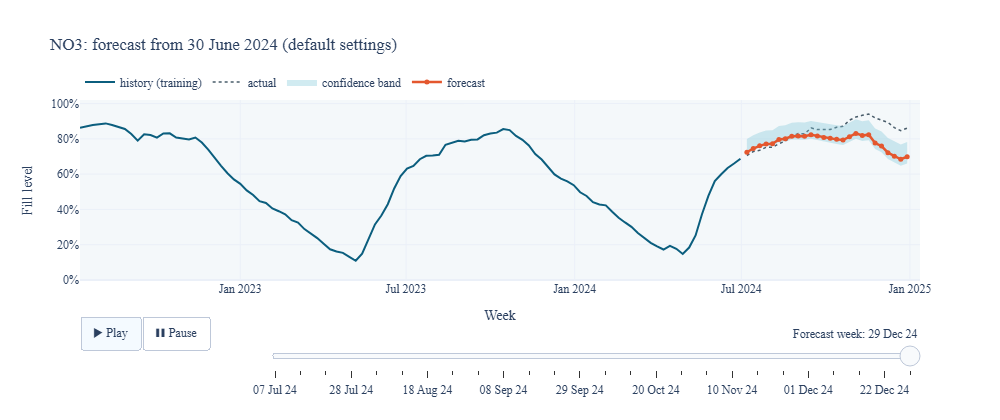

In [22]:
result = forecast_fill(FILL["NO3"], exog=exog_for("NO3", best_sources), origin="2024-06-30", future_exog="observed",
                       history_weeks=52 * best_years, memory=best_memory, quantiles=(0.1, 0.9), **BEST)
print(f"MAE {result['mae']:.3f}, {result['seconds']:.2f} s")
fig = forecast_animation(result, title="NO3: forecast from 30 June 2024 (default settings)")
fig.update_layout(updatemenus=[], sliders=[])   # no buttons in a static image
fig.show()

**Findings.**
- **Baseline:** the normal seasonal curve alone (the week-of-year average) has a mean
  absolute error of 0.086 (8.6 percentage points of fill level) over the 60 backtests
  (5 price areas × 12 start weeks, 26 weeks ahead). Every useful model must beat this.
- **Model (test 2):** the lag-based linear model with 2 lags and learning rate 0.05 was best
  (0.057). A low learning rate (0.005) learns too slowly and ends up at the baseline;
  0.1 is slightly worse again. SNARIMAX did best with differencing (p=1, d=1: 0.062);
  extra MA or seasonal terms did not help on top of the climatology.
- **Data sources (test 3):** with the *observed* future weather (a backtest), precipitation
  and temperature together gave the lowest error (0.052): rain fills the reservoirs, and
  temperature decides when snow melts. When the future weather is replaced by normal weather
  (a real forecast), no input beats the model without inputs, so the gain comes from knowing
  the weather, not from the past weather. EUR and USD helped a little in the backtest
  (0.053), but they made the real forecast worse, so I see that as a coincidence rather than
  a cause.
- **History and memory (test 4):** more history is better: 10 years gave 0.050, 3 years
  0.065. A short memory of 4 weeks for the inputs was best.
- **Band (bonus, test 5):** the 80% band from the quantile models widens with the horizon
  (0.10 → 0.15), but it contains only 60% of the actual values. The quantile models learn
  the error one step at a time inside the training data, while the real forecast error
  grows as forecasts are fed back. The band is therefore too narrow and should be read as a
  lower bound of the uncertainty.
- **Default in the app:** lag-based model, p=2, learning rate 0.05, 10 years, 26 weeks
  ahead, precipitation + temperature with memory 4, observed inputs. MAE 0.050 against 0.086
  for the baseline (42% lower). Each forecast takes about 0.01 s (0.4 s with the band),
  so the app can re-run it on every change.

## 7. Sliding window correlation: weather and reservoirs
The app's "Weather and reservoirs" page correlates a weather property with a reservoir
variable in a sliding window, with the weather shifted by a lag. The same function is
used here to look for relationships that could help the forecasts. The reservoir variable
is the weekly *change* in fill level: it reacts to the inflow of that week, while the
level is the running sum of all earlier changes.

In [23]:
from plotly.subplots import make_subplots

DATA_COLOUR, OUTLIER_COLOUR, BOUNDARY_COLOUR = FJORD, CORAL, SLATE


def sliding_window_correlation(
    weather: pd.Series,
    reservoir: pd.Series,
    window: int = 26,
    lag: int = 0,
):
    """Sliding window correlation (SWC) between a weather variable and a reservoir variable.

    The weather series is shifted `lag` steps forward in time, so lag = 4 compares the
    reservoir in week t with the weather in week t - 4 (the weather *leads*). In every
    window of `window` consecutive weeks, the Pearson correlation is computed; the result
    shows how the relationship changes over the years and seasons.

    Returns (figure, DataFrame with the aligned series and the correlation).
    """
    data = pd.concat(
        {"weather": weather.shift(lag), "reservoir": reservoir}, axis=1
    ).dropna()
    data["correlation"] = data["weather"].rolling(window, min_periods=window).corr(data["reservoir"])

    fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08,
                        row_heights=[0.55, 0.45],
                        subplot_titles=["Both series, standardised (z-scores)",
                                        f"Correlation in a sliding window of {window} weeks"])
    for col, name, colour in (("reservoir", reservoir.name or "reservoir", DATA_COLOUR),
                              ("weather", f"{weather.name or 'weather'} (lag {lag} w)", OUTLIER_COLOUR)):
        z = (data[col] - data[col].mean()) / data[col].std()
        fig.add_scatter(x=data.index, y=z, mode="lines", name=name, line=dict(color=colour, width=1.2),
                        row=1, col=1)
    fig.add_scatter(x=data.index, y=data["correlation"], mode="lines", name="correlation",
                    line=dict(color=BOUNDARY_COLOUR, width=1.5), fill="tozeroy",
                    fillcolor="rgba(27,154,170,0.25)", row=2, col=1)
    fig.add_hline(y=0, line=dict(color=BOUNDARY_COLOUR, width=1), row=2, col=1)
    fig.update_yaxes(range=[-1, 1], title_text="r", row=2, col=1)
    fig.update_layout(height=600, hovermode="x unified",
                      legend=dict(orientation="h", y=1.06, yanchor="bottom", x=0))
    return fig, data

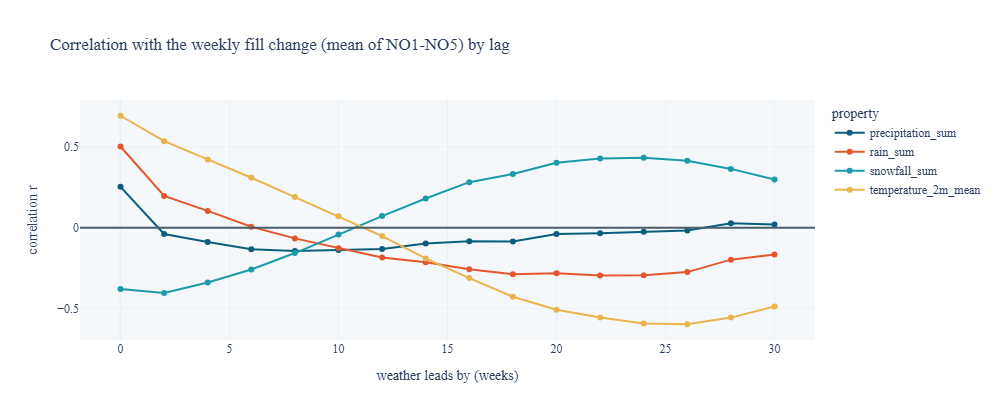

In [24]:
# Correlation over the whole period for lags 0-30 weeks: which weather leads the reservoirs?
change = {a: nve[nve["area"] == a].set_index("dato_Id")["endring_fyllingsgrad"].sort_index() for a in TEST_AREAS}
rows = []
for area in TEST_AREAS:
    w = weather_weekly[weather_weekly["area"] == area].set_index("week")
    for prop in ("precipitation_sum", "snowfall_sum", "rain_sum", "temperature_2m_mean"):
        for lag in range(0, 31, 2):
            both = pd.concat([w[prop].shift(lag), change[area]], axis=1).dropna()
            rows.append({"area": area, "property": prop, "lag": lag, "r": both.corr().iloc[0, 1]})
lags = pd.DataFrame(rows)
fig = px.line(lags.groupby(["property", "lag"])["r"].mean().reset_index(), x="lag", y="r", color="property",
              markers=True, title="Correlation with the weekly fill change (mean of NO1-NO5) by lag",
              labels={"lag": "weather leads by (weeks)", "r": "correlation r"})
fig.add_hline(y=0, line_color=SLATE)
fig.show()

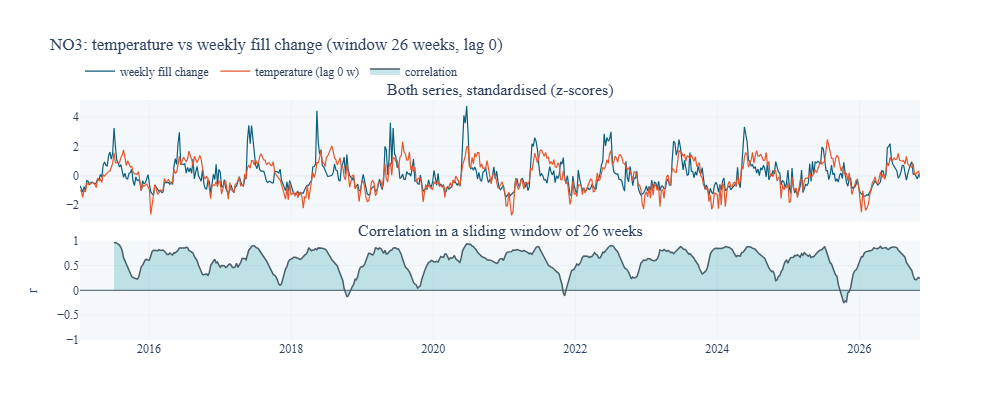

In [25]:
# Sliding window: NO3 temperature vs weekly fill change, 26-week window, no lag
w3 = weather_weekly[weather_weekly["area"] == "NO3"].set_index("week")
fig, data = sliding_window_correlation(w3["temperature_2m_mean"].rename("temperature"),
                                       change["NO3"].rename("weekly fill change"), window=26, lag=0)
fig.update_layout(title="NO3: temperature vs weekly fill change (window 26 weeks, lag 0)")
fig.show()

**Findings.**
- **Temperature** has the strongest relation to the weekly fill change, at lag 0
  (r ≈ 0.65–0.76): warm weeks melt snow, and the reservoirs rise in the same week.
- **Snowfall** is negative at lag 0 (snow does not run off, and cold weeks are low-inflow
  weeks), but turns *positive* when it leads by about 20–26 weeks (r ≈ 0.4–0.5): the winter's
  snow comes back as inflow in spring. The delay differs between the areas (about 19 weeks
  in NO1, 23 in NO4 and 26 in NO5).
- **Rain** (r ≈ 0.45–0.6) is a clearly better predictor than total precipitation (≈ 0.25),
  because precipitation also counts the snow, which does not run off at once.
- The sliding window shows that the relation is **not stable**: for temperature in NO3 the
  26-week correlation goes from about −0.25 to 0.96. It is strongest in windows that contain
  the spring melt and weak in the winter, when the reservoirs are drained for power whatever
  the weather. A single correlation over the whole period hides this, which is why a lag and
  a window are useful in the app.

## 8. AI usage
I used Claude Code as a pair programmer in VS Code, as in parts 1–3:
- **Notebook:** finding Norges Bank's SDMX API and the open-meteo time-zone parameter, the
  code for the currency function and the time-zone checks, and the River forecasting function
  (deseasonalising, AdaGrad when plain SGD diverged, the quantile models for the band) and
  the backtests.
- **Streamlit:** the GeoJSON map with click selection (`on_select` callback), the shared
  session state, the theme, the conversion of all plots to Plotly, the new pages and the
  forecast animation. The pages were tested with Streamlit's `AppTest`.
- **Data:** a resumable script for the weather history, since the download hit open-meteo's
  hourly and daily limits.


## 9. Log
In this last part I finished the app and added forecasting.

I started with a sketch in figman of all pages before writing code. With more pages combining several
sources, grouping the menu by data source no longer worked, so I grouped it by task:
overview, explore, anomalies and predict. The map became the front page and the main
selector: a click on an area stores it in session state, and every page uses it. Clicking
was harder than expected, because Streamlit does not allow a widget's value to be changed
after it is drawn. The solution was a callback that runs before the page is drawn again.
The LineChartColumn page became a tab of the reservoir page, since it shows the same data.

The time zones turned out to matter less than I feared, as long as everything is put on
the same weeks. Magasinstatistikk labels each week by its Sunday, so I made weeks ending on
Sunday from Norwegian local days for the weather and the currency. ENTSO-E is in UTC and
must be converted before grouping.

The weather history was the slowest part. Twelve years of daily weather for five points in
eight areas is about 12,000 open-meteo calls, more than the free daily limit, so the
download keeps every point in a file and continues where it stopped. It ran over two days.
The app reads the weekly result from MongoDB, so it does not download anything for the map.

For the forecast I chose a weekly resolution, the native one of the reservoir data. A plain
SNARIMAX on the fill level was worse than just using the normal seasonal curve, so I remove
the curve first and model only the deviation from it. With weather inputs, River's default
SGD optimiser exploded, and AdaGrad fixed it. The tests showed that precipitation and
temperature help when the future weather is known, but with normal weather instead, the
model without inputs was just as good. More history was always better. As a bonus I added
confidence bands with quantile loss. They widen with the horizon, but they are too narrow
(60% instead of 80% coverage), which I report rather than hide.

Playing with the sliding window correlation was the most surprising part. Snowfall looks
negatively related to filling, but with a lag of about 20 weeks it becomes clearly
positive: the snow comes back as spring inflow. Temperature works in the same week, and the
correlations change a lot with the season, strong in spring and weak in winter.

Following the peer review, all plots are now Plotly with one Nordic colour theme.